# Advanced LLM Fine Tuning · Lesson 2 · Audit synthetic training data

You maintain an invoice parser for accounts payable. An invoice says USD, but a proposed
training target says GBP. Both currencies fit the schema. If that mismatch reaches the
next fine-tune, the parser can learn to send a correct-looking amount in the wrong currency.

What does fixing noisy labels buy when the inputs and training budget stay fixed?
Run on a Colab T4. Budget about 25–35 minutes, including setup and evaluation.
[Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/1-build-the-data/02-audit-synthetic-data).

## Runtime

Select a Tesla T4 in Colab. Each branch runs in sequence. Model downloads use the
public Hugging Face checkpoint, pinned by revision. The shared runtime can reuse
its weight cache. The material below embeds the invoice fixtures and training code.

In [1]:
import subprocess
import sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *['transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0']], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0'], returncode=0)

In [2]:
import torch
if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name(0):
    raise RuntimeError("Select a Tesla T4 runtime in Colab before running this notebook.")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


## Invoice fixtures

The synthetic input and gold record come from a versioned scenario. The scorer compares
generated JSON with the gold record independently of model training. The release set stays
out of this lesson.

In [3]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

## Completion masking

The prefix-stable masking and preference helpers below adapt Apache-2.0 recipe code from
the Together Post-Training Cookbook. The shared helpers build a causal training sequence
while marking just the answer tokens and end marker as targets.

In [4]:
# SPDX-License-Identifier: Apache-2.0
"""Portable training functions from the Together Post-Training Cookbook.

Adapted from togethercomputer/post-training-cookbook at
226e03ca225d6f13434047cf0f45ab3070a29801. See third_party for the Apache licence
and the original paths. The hosted training and provisioning code is replaced
by notebook-local PyTorch and typed fixtures.
"""

from __future__ import annotations

import random
from collections import Counter
from collections.abc import Callable, Iterable, Sequence
from dataclasses import dataclass, field
from typing import NamedTuple, TypeVar

import torch
import torch.nn.functional as F


class Turn(NamedTuple):
    prompt: list[int]
    completion: list[int]


class MaskedSequence(NamedTuple):
    input_ids: list[int]
    completion_mask: list[int]


def split_turns(turns: Iterable[Turn]) -> list[MaskedSequence]:
    """Build prefix-stable sequences with a token-aligned completion mask."""
    sequences: list[MaskedSequence] = []
    emitted: list[int] = []
    mask: list[int] = []
    for prompt, completion in turns:
        if len(prompt) < len(emitted) or prompt[: len(emitted)] != emitted:
            if emitted:
                sequences.append(MaskedSequence(emitted, mask))
            mask = [0] * len(prompt)
        else:
            mask = mask + [0] * (len(prompt) - len(emitted))
        emitted = prompt + completion
        mask = mask + [1] * len(completion)
    if emitted:
        sequences.append(MaskedSequence(emitted, mask))
    return sequences


def masked_logp_sum(logprobs: torch.Tensor, mask: Sequence[float]) -> torch.Tensor:
    """Sum target-aligned response log probabilities and retain gradients."""
    if logprobs.ndim != 1 or len(mask) != logprobs.shape[0]:
        raise ValueError("The response mask must match the one-dimensional target log probabilities.")
    weights = torch.as_tensor(mask, dtype=logprobs.dtype, device=logprobs.device)
    return (logprobs * weights).sum()


def make_dpo_loss(
    ref_sums: Sequence[float],
    masks: Sequence[Sequence[float]],
    *,
    beta: float,
    label_smoothing: float = 0.0,
) -> Callable[[Sequence[torch.Tensor]], torch.Tensor]:
    """Close over fixed reference scores and response masks for chosen/rejected pairs."""
    if not ref_sums or len(ref_sums) != len(masks) or len(ref_sums) % 2:
        raise ValueError("Supply at least one complete pair and one mask for each reference score.")
    if beta <= 0.0 or not 0.0 <= label_smoothing <= 0.5:
        raise ValueError("Beta must be positive and label smoothing must be between 0 and 0.5.")
    branch_size = len(ref_sums)

    def loss_fn(policy_logprobs: Sequence[torch.Tensor]) -> torch.Tensor:
        if len(policy_logprobs) != branch_size:
            raise ValueError(f"Expected {branch_size} policy log-probability tensors.")
        policy = torch.stack([masked_logp_sum(values, mask) for values, mask in zip(policy_logprobs, masks, strict=True)])
        reference = policy.new_tensor(ref_sums)
        delta = policy - reference
        margin = beta * (delta[0::2] - delta[1::2])
        return (-(1.0 - label_smoothing) * F.logsigmoid(margin) - label_smoothing * F.logsigmoid(-margin)).mean()

    return loss_fn


def compute_overlong_penalty(
    response_length: int,
    max_response_length: int,
    overlong_buffer_len: int,
    penalty_factor: float = 1.0,
) -> float:
    """Apply the cookbook's DAPO soft penalty near a generation cap."""
    if overlong_buffer_len <= 0:
        return 0.0
    expected_len = max_response_length - overlong_buffer_len
    exceed_len = response_length - expected_len
    return min(-exceed_len / overlong_buffer_len * penalty_factor, 0.0)


Item = TypeVar("Item")


def oversample_until_kept(
    draw_batch: Callable[[], Iterable[Item]],
    *,
    is_kept: Callable[[Item], bool],
    target: int,
    max_attempts: int,
) -> tuple[list[Item], int]:
    """Keep rejected groups in the audit trail while bounding draws."""
    if target <= 0 or max_attempts <= 0:
        raise ValueError("Target and maximum attempts must be positive.")
    items: list[Item] = []
    kept = 0
    for attempts in range(1, max_attempts + 1):
        for item in draw_batch():
            items.append(item)
            if is_kept(item):
                kept += 1
                if kept >= target:
                    return items, attempts
    return items, max_attempts


@dataclass(frozen=True)
class TeacherRequest:
    key: str
    messages: Sequence[dict[str, str]]
    meta: dict[str, object] = field(default_factory=dict)


@dataclass(frozen=True)
class TeacherOutput:
    content: str
    ok: bool = True
    truncated: bool = False


def sft_rows(
    requests: Sequence[TeacherRequest],
    outputs: dict[str, TeacherOutput],
    *,
    reject_reason: Callable[[TeacherRequest, TeacherOutput], str | None] | None = None,
) -> tuple[list[dict[str, object]], Counter[str]]:
    """Convert verified procedural teacher outputs to SFT rows and count exclusions."""
    rows: list[dict[str, object]] = []
    dropped: Counter[str] = Counter()
    for request in requests:
        output = outputs.get(request.key)
        if output is None:
            dropped["missing"] += 1
            continue
        if not output.ok:
            dropped["failed"] += 1
            continue
        if output.truncated:
            dropped["truncated"] += 1
            continue
        content = output.content.strip()
        if not content:
            dropped["empty"] += 1
            continue
        reason = reject_reason(request, output) if reject_reason is not None else None
        if reason is not None:
            dropped[reason] += 1
            continue
        assistant = {"role": "assistant", "content": content}
        rows.append({"id": request.key, "messages": [*request.messages, assistant], "meta": dict(request.meta)})
    return rows, dropped


def mix(*groups: Sequence[Item], seed: int = 0) -> list[Item]:
    """Concatenate row groups and shuffle them deterministically."""
    rows = [row for group in groups for row in group]
    random.Random(seed).shuffle(rows)
    return rows

## Training and scoring

A common prompt, batch schedule and scorer make each comparison interpretable. The paired
uncertainty calculation resamples whole layout families, so repeated layouts do not count
as independent evidence.

In [5]:
"""Shared notebook-local text training and measurement for lessons 01–03."""
from __future__ import annotations

import gc
import hashlib
import importlib.metadata
import json
import random
import statistics
import time
from collections import defaultdict
from pathlib import Path

import torch

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
SEED = 42
MAX_TOKENS = 1536
MAX_NEW_TOKENS = 384
BATCH = 2



def canonical_json(record):
    return json.dumps(record, ensure_ascii=False, separators=(",", ":"))


def ordered_by_family(items):
    by_family = defaultdict(list)
    for invoice in items:
        by_family[invoice.family].append(invoice)
    randomizer = random.Random(SEED)
    families = list(by_family)
    randomizer.shuffle(families)
    for rows in by_family.values():
        randomizer.shuffle(rows)
    return [
        by_family[family][offset]
        for offset in range(max(map(len, by_family.values()), default=0))
        for family in families
        if offset < len(by_family[family])
    ]


def lesson_prompts(catalog):
    """Choose one training exemplar and preserve dataset order after seeded sampling."""
    train = ordered_by_family([invoice for invoice in catalog if invoice.split == "train"])
    if len(train) < 3:
        raise ValueError("The shared catalogue must contain at least three training invoices.")
    exemplar, *train = train
    teach_splits = {"familiar", "novel", "independent"}
    evaluation = [invoice for invoice in catalog if invoice.split in teach_splits]
    if not evaluation or set(item.split for item in evaluation) != teach_splits:
        raise ValueError("The three fixed teaching slices must be present.")
    return exemplar, train, evaluation


def prompt_messages(invoice, exemplar):
    return [
        {"role": "system", "content": VISIBLE_CONTRACT},
        {"role": "user", "content": invoice_text(exemplar)},
        {"role": "assistant", "content": canonical_json(invoice_record(exemplar))},
        {"role": "user", "content": invoice_text(invoice)},
    ]


def encode_prompt(tokenizer, invoice, exemplar):
    return tokenizer.apply_chat_template(
        prompt_messages(invoice, exemplar), tokenize=True, add_generation_prompt=True,
    )


def encode_supervision(tokenizer, invoice, answer, exemplar):
    prompt = encode_prompt(tokenizer, invoice, exemplar)
    completion = tokenizer.encode(answer, add_special_tokens=False) + [tokenizer.eos_token_id]
    sequence, = split_turns([Turn(prompt, completion)])
    if len(sequence.input_ids) > MAX_TOKENS or len(completion) + 1 > MAX_NEW_TOKENS:
        raise ValueError(f"Invoice {invoice.key} exceeds the fixed token budget.")
    return sequence


def right_pad(examples, pad_id, device):
    width = max(len(example.input_ids) for example in examples)
    ids, attention, labels = [], [], []
    for example in examples:
        n_pad = width - len(example.input_ids)
        ids.append(example.input_ids + [pad_id] * n_pad)
        attention.append([1] * len(example.input_ids) + [0] * n_pad)
        labels.append([token if mask else -100 for token, mask in zip(
            example.input_ids, example.completion_mask, strict=True,
        )] + [-100] * n_pad)
    return {
        key: torch.tensor(rows, dtype=torch.long, device=device)
        for key, rows in (("input_ids", ids), ("attention_mask", attention), ("labels", labels))
    }


def load_model(encoding, *, adapter=None, trainable=False):
    from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig

    torch.manual_seed(SEED)
    if encoding == "nf4":
        quant = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16,
        )
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, revision=REVISION, quantization_config=quant, torch_dtype=torch.float16,
            device_map={"": 0}, attn_implementation="sdpa",
        )
    elif encoding == "fp16":
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, revision=REVISION, torch_dtype=torch.float16, attn_implementation="sdpa",
        ).to("cuda")
    else:
        raise ValueError(f"Unsupported weight encoding {encoding!r}.")
    if not trainable and adapter is None:
        return model
    if trainable and encoding == "nf4":
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)
    if adapter is not None:
        return PeftModel.from_pretrained(model, str(adapter), is_trainable=trainable)
    if not trainable:
        raise ValueError("An adapter is required for evaluating a trained arm.")
    return get_peft_model(model, LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.0, bias="none",
        task_type="CAUSAL_LM", target_modules=["q_proj", "v_proj"],
    ))


def adapter_train(model, schedule, objective, *, learning_rate, use_cuda):
    """Both arms share the same schedule, optimiser and gradient policy."""
    params = [param for param in model.parameters() if param.requires_grad]
    if not params or not schedule:
        raise ValueError("Expected trainable parameters and a nonempty update schedule.")
    optimiser = torch.optim.AdamW(params, lr=learning_rate)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda, init_scale=512, growth_interval=10_000)
    torch.manual_seed(SEED)
    model.train()
    model.config.use_cache = False
    if use_cuda:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    losses, supervised_count, batch_token_count, skipped = [], 0, 0, 0
    for batch in schedule:
        optimiser.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
            loss, supervised, batch_tokens = objective(model, batch)
        if not torch.isfinite(loss).item():
            raise FloatingPointError("A non-finite training loss invalidates the comparison.")
        scaler.scale(loss).backward()
        scaler.unscale_(optimiser)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        previous_scale = scaler.get_scale()
        scaler.step(optimiser)
        scaler.update()
        skipped += int(scaler.get_scale() < previous_scale)
        losses.append(float(loss.detach().cpu()))
        supervised_count += supervised
        batch_token_count += batch_tokens
    if use_cuda:
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return {
        "attempted_updates": len(schedule),
        "updates": len(schedule) - skipped,
        "supervised_response_tokens": supervised_count,
        "unpadded_input_tokens": batch_token_count,
        "seconds": elapsed,
        "supervised_tokens_per_second": supervised_count / max(elapsed, 1e-9),
        "peak_gib": torch.cuda.max_memory_allocated() / 2**30 if use_cuda else None,
        "losses": losses,
        "trainable_parameters": sum(parameter.numel() for parameter in params),
    }


def sft_objective(pad_id, device):
    def loss_for(model, examples):
        batch = right_pad(examples, pad_id, device)
        loss = model(**batch).loss
        supervised = int(batch["labels"][:, 1:].ne(-100).sum().item())
        if not supervised:
            raise ValueError("An update needs at least one response token.")
        unpadded = int(batch["attention_mask"].sum().item())
        return loss, supervised, unpadded
    return loss_for


def make_schedule(examples, batch_size=BATCH):
    if not examples or batch_size <= 0:
        raise ValueError("Expected training examples and a positive batch size.")
    return [examples[start : start + batch_size] for start in range(0, len(examples), batch_size)]


def predictions(model, tokenizer, eval_items, exemplar, batch_size=16):
    model.eval()
    device = model.get_input_embeddings().weight.device
    outputs = []
    for start in range(0, len(eval_items), batch_size):
        group = eval_items[start : start + batch_size]
        prompts = [encode_prompt(tokenizer, item, exemplar) for item in group]
        width = max(map(len, prompts))
        if width + MAX_NEW_TOKENS > MAX_TOKENS:
            raise ValueError("Evaluation prompt and fixed decode cap exceed the token budget.")
        ids = torch.tensor([[tokenizer.pad_token_id] * (width - len(p)) + p for p in prompts], device=device)
        mask = torch.tensor([[0] * (width - len(p)) + [1] * len(p) for p in prompts], device=device)
        with torch.inference_mode():
            generated = model.generate(
                input_ids=ids, attention_mask=mask,
                do_sample=False, num_beams=1, max_new_tokens=MAX_NEW_TOKENS,
                pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
                use_cache=True, temperature=None, top_p=None, top_k=None,
            )
        for item, tokens in zip(group, generated[:, width:].tolist(), strict=True):
            stopped = tokenizer.eos_token_id in tokens
            if stopped:
                tokens = tokens[:tokens.index(tokenizer.eos_token_id)]
            answer = tokenizer.decode(tokens, skip_special_tokens=True)
            outputs.append({
                "key": item.key, "split": item.split, "family": item.family,
                "completed": stopped, "answer": answer, "reference": invoice_record(item),
                "completion_tokens": len(tokens), **score_record(answer, item),
            })
    return outputs


def rules_predictions(items):
    rows = []
    for item in items:
        result = rules_extract(invoice_text(item))
        rows.append({
            "key": item.key, "split": item.split, "family": item.family,
            "completed": result is not None, "answer": result, "reference": invoice_record(item),
            **score_record(result if result is not None else "", item),
        })
    return rows


def paired_family_interval(reference, candidate, repeats=1000):
    """Pair by invoice, then resample whole layout families within a slice."""
    deltas = defaultdict(list)
    old_by_key = {row["key"]: row for row in reference}
    if set(old_by_key) != {row["key"] for row in candidate}:
        raise ValueError("Paired comparisons require the same unique invoice keys.")
    for row in candidate:
        old = old_by_key[row["key"]]
        if (old["family"], old["split"]) != (row["family"], row["split"]):
            raise ValueError("An invoice moved family or split.")
        deltas[row["family"]].append(int(row["exact"]) - int(old["exact"]))
    groups = list(deltas.values())
    if len(groups) < 2:
        return None
    randomizer = random.Random(SEED)
    draws = []
    for _ in range(repeats):
        sampled_groups = randomizer.choices(groups, k=len(groups))
        draws.append(sum(map(sum, sampled_groups)) / sum(map(len, sampled_groups)))
    draws.sort()
    return [draws[int(0.025 * (repeats - 1))], draws[int(0.975 * (repeats - 1))]]


def free_gpu():
    """Collect dropped references between sequential Colab arms."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def save_results(lesson, scores, training, comparisons, **diagnostics):
    import matplotlib
    import matplotlib.pyplot as plt

    seed = SEED
    grouped = {
        name: {
            split: {
                "n": len(rows_in_split),
                **{
                    metric: statistics.mean(float(row[metric]) for row in rows_in_split)
                    for metric in ("valid", "exact", "completed", "fields", "row_f1")
                },
            }
            for split in ("familiar", "novel", "independent")
            if (rows_in_split := [row for row in rows if row["split"] == split])
        }
        for name, rows in scores.items()
    }
    intervals = {}
    for baseline, candidate in comparisons:
        intervals[f"{candidate} minus {baseline}"] = {
            split: interval
            for split in ("familiar", "novel", "independent")
            if (interval := paired_family_interval(
                [row for row in scores[baseline] if row["split"] == split],
                [row for row in scores[candidate] if row["split"] == split],
            )) is not None
        }
    roster = {
        row["key"]: {"split": row["split"], "family": row["family"]}
        for row in next(iter(scores.values()))
    }
    report = {
        "model_id": MODEL, "model_revision": REVISION, "seed": seed,
        "versions": {name: importlib.metadata.version(name) for name in ("torch", "transformers", "peft")},
        "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU smoke",
        "held_out_roster_sha256": hashlib.sha256(
            json.dumps(roster, sort_keys=True, separators=(",", ":")).encode()
        ).hexdigest(),
        "scores": grouped, "paired_family_intervals": intervals, "training": training,
        "diagnostics": diagnostics,
    }
    payload = Path("results")
    payload.mkdir(exist_ok=True)
    (payload / f"{lesson}-report.json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    (payload / f"{lesson}-predictions.json").write_text(json.dumps(scores, indent=2) + "\n", encoding="utf-8")
    print(json.dumps({key: value for key, value in report.items() if key != "training"}, indent=2))
    print(json.dumps({
        arm: {key: value for key, value in metrics.items() if key != "losses"}
        for arm, metrics in training.items()
    }, indent=2))

    matplotlib.rcParams["svg.fonttype"] = "none"
    fig, axes = plt.subplots(1, len(grouped[next(iter(grouped))]), figsize=(11, 4), squeeze=False, sharey=True)
    for axis, split in zip(axes[0], grouped[next(iter(grouped))], strict=True):
        names = list(grouped)
        values = [grouped[name][split]["exact"] for name in names]
        axis.barh(names, values, color="#357e72")
        axis.set_title(split.title())
        axis.set_xlim(0, 1)
        axis.set_xlabel("Exact record rate")
        axis.grid(axis="x", alpha=0.2)
    axes[0, 0].invert_yaxis()
    fig.suptitle("Complete-record accuracy on the held-out invoice slices")
    fig.tight_layout()
    fig.savefig(payload / f"{lesson}-exact.svg", bbox_inches="tight")
    from IPython.display import SVG, display
    display(SVG(filename=str(payload / f"{lesson}-exact.svg")))
    plt.close(fig)
    return report

In [6]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=REVISION)
if tokenizer.pad_token_id is None or tokenizer.eos_token_id is None:
    raise ValueError("The pinned tokenizer must supply padding and completion markers.")
catalogue = make_catalog()
exemplar, training_items, evaluation_items = lesson_prompts(catalogue)
print("Teaching evaluation counts:", dict(Counter(x.split for x in evaluation_items)))
print("One train-only prompt exemplar:", exemplar.key)

Teaching evaluation counts: {'familiar': 96, 'novel': 96, 'independent': 48}
One train-only prompt exemplar: SF-898991


## Which documents can the model see?

Reserve the exemplar, then draw a balanced training sample from every training family.
The familiar evaluation families have known layouts and new suppliers. Novel and
independent slices have new layouts. All are synthetic. The release split stays reserved.

In [7]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")
TRAIN_ROWS = 192
FAULT_PERIOD = 3
EVAL_BATCH = 16
LEARNING_RATE = 2e-4
DEVICE = "cuda"
chosen = training_items[:TRAIN_ROWS]
reserved = [invoice for invoice in catalogue if invoice.split != "train"]

## Why keep two records for one invoice?

Offset the faults within each supplier family so no training family lies entirely outside
the corruption schedule. Hash the visible invoice independently of its answer. Drop exact
duplicate documents once. Compare each remaining candidate with the source record, and
correct the label on the verified arm. The raw arm retains the original candidate.

In [8]:
"""Deduplicate visible invoices and verify each retained training target."""

import hashlib
from collections import Counter
from copy import deepcopy


RAW = "Raw labels"
VERIFIED = "Verified labels"
FAULTS = ("wrong currency", "dropped row", "wrong total")
DUPLICATE = "duplicate visible invoice"
TEACHING_SPLITS = ("familiar", "novel", "independent")


def visible_hash(invoice):
    return hashlib.sha256(invoice_text(invoice).encode("utf-8")).hexdigest()


def assert_split_lineage(catalogue, chosen, exemplar, held):
    split_counts = Counter(row.split for row in catalogue)
    if split_counts != SPLIT_SIZES:
        raise AssertionError("The catalogue split counts changed.")
    if len({row.key for row in catalogue}) != len(catalogue):
        raise AssertionError("Invoice identifiers must be unique in the catalogue.")
    if len({visible_hash(row) for row in catalogue}) != len(catalogue):
        raise AssertionError("The catalogue contains an unexpected visible duplicate.")
    for key in ("supplier", "family"):
        splits_by_group = {}
        for row in catalogue:
            group = getattr(row, key)
            if splits_by_group.setdefault(group, row.split) != row.split:
                raise AssertionError(f"A {key} appears in more than one split.")
    training = {row.key: row for row in catalogue if row.split == "train"}
    selected = [exemplar, *chosen]
    if len({row.key for row in selected}) != len(selected):
        raise AssertionError("The training inputs must be unique and exclude the exemplar.")
    if any(training.get(row.key) != row for row in selected):
        raise AssertionError("A training input or exemplar lacks training-split lineage.")
    expected_eval = [row for row in catalogue if row.split in TEACHING_SPLITS]
    if held != expected_eval:
        raise AssertionError("The evaluation roster must contain the locked teaching splits in order.")
    return dict(split_counts)


def corrupt_record(gold, mode):
    edited = deepcopy(gold)
    if mode == "wrong currency":
        edited["currency"] = "GBP" if edited["currency"] != "GBP" else "USD"
    elif mode == "dropped row":
        edited["line_items"].pop()
    elif mode == "wrong total":
        if edited["total_minor"] is None:
            raise ValueError("The wrong-total operation requires a visible total.")
        edited["total_minor"] += 101
    elif mode != "none":
        raise ValueError(f"Unknown corruption {mode!r}.")
    return edited


def audit_labels(train_items, forbidden_items, *, fault_period=3):
    """Record candidate lineage before running a separate check on retained labels."""
    if fault_period < 1:
        raise ValueError("Fault period must be a positive number of examples.")
    forbidden = {visible_hash(row) for row in forbidden_items}
    family_offsets, family_order = Counter(), {}
    pool = []
    for position, row in enumerate(train_items):
        offset = family_offsets[row.family]
        order = family_order.setdefault(row.family, len(family_order))
        phase = offset - order % fault_period
        mode = "none"
        if phase >= 0 and phase % fault_period == 0:
            mode = FAULTS[(phase // fault_period + order // fault_period) % len(FAULTS)]
        family_offsets[row.family] += 1
        pool.append((row, mode))
        if position % 11 == 0:
            pool.append((row, mode))

    raw, verified, lineage, seen = [], [], [], {}
    reasons = Counter()
    for position, (row, mode) in enumerate(pool, start=1):
        digest = visible_hash(row)
        if digest in forbidden:
            raise ValueError("A candidate prompt duplicates a held-out invoice or the prompt exemplar.")
        first = seen.setdefault(digest, position)
        detail = {
            "candidate": position, "kept_candidate": first, "invoice_key": row.key,
            "family": row.family, "layout": row.layout, "visible_sha256": digest, "injected_fault": mode,
        }
        lineage.append(detail)
        if first != position:
            detail["disposition"] = "duplicate"
            reasons[DUPLICATE] += 1
            continue

        gold = invoice_record(row)
        candidate = corrupt_record(gold, mode)
        observed = score_record(candidate, row)
        exact = observed["exact"]
        if not observed["valid"] or exact != (mode == "none"):
            raise AssertionError("The fault must change exactness without breaking the schema.")
        if not exact:
            reasons[mode] += 1
        corrected = candidate if exact else gold
        if not score_record(corrected, row)["exact"]:
            raise AssertionError("A corrected record still disagrees with the fixture.")
        detail["disposition"] = "unchanged" if exact else "corrected"
        raw.append((row, canonical_json(candidate)))
        verified.append((row, canonical_json(corrected)))

    assert len(pool) == len(raw) + reasons[DUPLICATE]
    assert sum(entry["disposition"] == "corrected" for entry in lineage) == sum(reasons[mode] for mode in FAULTS)
    return raw, verified, reasons, lineage


def prepared_labels(train_items, forbidden_items):
    """Preserve the shared lesson smoke's compact return shape."""
    raw, verified, reasons, _ = audit_labels(train_items, forbidden_items)
    return raw, verified, reasons

In [9]:
"""Check the matched comparison and export evidence for each teaching decision."""


def checked_schedule(tokenizer, raw, verified, exemplar):
    schedules, expected = {}, {}
    expected_documents = [row for row, _ in raw]
    if expected_documents != [row for row, _ in verified]:
        raise AssertionError("Both arms must retain the same ordered invoice records.")

    prompts = [encode_prompt(tokenizer, row, exemplar) for row in expected_documents]
    for name, rows in ((RAW, raw), (VERIFIED, verified)):
        examples = []
        for index, (invoice, answer) in enumerate(rows):
            prompt = prompts[index]
            response = tokenizer.encode(answer, add_special_tokens=False) + [tokenizer.eos_token_id]
            example = encode_supervision(tokenizer, invoice, answer, exemplar)
            if example.input_ids != prompt + response:
                raise AssertionError(f"Unexpected token lineage for {invoice.key}.")
            if example.completion_mask != [0] * len(prompt) + [1] * len(response):
                raise AssertionError(f"Unexpected response mask for {invoice.key}.")
            examples.append(example)
        schedule = make_schedule(examples)
        for group in schedule:
            batch = right_pad(group, tokenizer.pad_token_id, "cpu")
            for index, example in enumerate(group):
                width = batch["labels"].shape[1]
                padding = width - len(example.input_ids)
                expected_mask = [bool(value) for value in example.completion_mask] + [False] * padding
                if batch["labels"][index].ne(-100).tolist() != expected_mask:
                    raise AssertionError("Prompt and padding tokens must be excluded from the loss.")
        schedules[name] = schedule
        expected[name] = {
            "rows": len(rows),
            "updates": len(schedule),
            "prompt_tokens": sum(map(len, prompts)),
            "supervised_response_tokens": sum(sum(example.completion_mask) for example in examples),
        }

    if [len(batch) for batch in schedules[RAW]] != [len(batch) for batch in schedules[VERIFIED]]:
        raise AssertionError("The batch schedule changed between arms.")
    return schedules, expected


def adapter_digest(model):
    digest = hashlib.sha256()
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        if ".lora_" not in name:
            raise AssertionError(f"Unexpected trainable weight {name}.")
        digest.update(name.encode("utf-8"))
        digest.update(parameter.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def assert_fit_budget(training, expected):
    baseline, corrected = training[RAW], training[VERIFIED]
    for name, stats in training.items():
        plan = expected[name]
        if stats["attempted_updates"] != plan["updates"] or stats["updates"] != plan["updates"]:
            raise AssertionError(f"{name} skipped a scheduled update.")
        if stats["supervised_response_tokens"] != plan["supervised_response_tokens"]:
            raise AssertionError(f"{name} saw an unexpected number of supervised tokens.")
        if stats["unpadded_input_tokens"] != plan["prompt_tokens"] + plan["supervised_response_tokens"]:
            raise AssertionError(f"{name} saw an unexpected number of unpadded tokens.")
        if stats["initial_adapter_sha256"] == stats["trained_adapter_sha256"]:
            raise AssertionError(f"{name} adapter did not change during training.")
    for metric in ("initial_adapter_sha256", "base_revision", "updates", "trainable_parameters"):
        if baseline[metric] != corrected[metric]:
            raise AssertionError(f"{metric} differs between matched arms.")


def paired_evidence(scores, evaluation_items):
    roster = [(row.key, row.family, row.split) for row in evaluation_items]
    for name, rows in scores.items():
        if [(row["key"], row["family"], row["split"]) for row in rows] != roster:
            raise AssertionError(f"{name} returned predictions on a different evaluation roster.")

    transitions = {split: Counter(fixed=0, regressed=0, both_exact=0, both_wrong=0) for split in TEACHING_SPLITS}
    examples = {}
    for item, raw, verified in zip(evaluation_items, scores[RAW], scores[VERIFIED], strict=True):
        if raw["exact"] == verified["exact"]:
            outcome = "both_exact" if raw["exact"] else "both_wrong"
        else:
            outcome = "fixed" if verified["exact"] else "regressed"
        transitions[item.split][outcome] += 1
        if outcome != "both_exact" and item.split in ("novel", "independent"):
            examples.setdefault(outcome, {
                "invoice_key": item.key, "split": item.split, "visible_invoice": invoice_text(item),
                "reference": invoice_record(item), RAW: raw["answer"], VERIFIED: verified["answer"],
            })
    return {
        split: {"n": sum(counts.values()), **dict(counts)}
        for split, counts in transitions.items()
    }, examples


def write_audit_evidence(raw, verified, lineage, evaluation_items, paired_examples):
    evidence = {
        "candidate_lineage": lineage,
        "changed_labels": [
            {
                "invoice_key": invoice.key, "visible_invoice": invoice_text(invoice),
                RAW: json.loads(raw_answer), VERIFIED: json.loads(verified_answer),
            }
            for (invoice, raw_answer), (_, verified_answer) in zip(raw, verified, strict=True)
            if raw_answer != verified_answer
        ],
        "held_out_documents": {invoice.key: invoice_text(invoice) for invoice in evaluation_items},
        "held_out_examples": paired_examples,
    }
    Path("results/02-audit.json").write_text(json.dumps(evidence, indent=2) + "\n", encoding="utf-8")
    return evidence

In [10]:
split_counts = assert_split_lineage(catalogue, chosen, exemplar, evaluation_items)
if len(chosen) != TRAIN_ROWS:
    raise AssertionError("The requested training roster is unavailable.")
retained_per_family = Counter(row.family for row in chosen)
train_families = {row.family for row in catalogue if row.split == "train"}
if set(retained_per_family) != train_families or len(set(retained_per_family.values())) != 1:
    raise AssertionError("Choose a whole number of balanced training-family rounds.")

raw, verified, ledger, lineage = audit_labels(
    chosen, [*reserved, exemplar], fault_period=FAULT_PERIOD,
)
coverage = {}
for entry in lineage:
    if entry["disposition"] == "duplicate":
        continue
    counts = coverage.setdefault(entry["family"], Counter(retained=0, corrected=0))
    counts["retained"] += 1
    counts["corrected"] += entry["disposition"] == "corrected"

schedules, expected_budget = checked_schedule(tokenizer, raw, verified, exemplar)
print("Catalogue split counts", split_counts)
print("Candidate and retained rows", len(lineage), len(raw))
print("Audit ledger", dict(ledger))
print("Retained and corrected by family", coverage)
print("Planned training exposure", expected_budget)

Catalogue split counts {'train': 576, 'dev': 72, 'familiar': 96, 'novel': 96, 'independent': 48, 'release': 120}
Candidate and retained rows 210 192
Audit ledger {'wrong currency': 21, 'duplicate visible invoice': 18, 'dropped row': 22, 'wrong total': 21}
Retained and corrected by family {'train-05': Counter({'retained': 8, 'corrected': 3}), 'train-18': Counter({'retained': 8, 'corrected': 3}), 'train-23': Counter({'retained': 8, 'corrected': 2}), 'train-13': Counter({'retained': 8, 'corrected': 3}), 'train-10': Counter({'retained': 8, 'corrected': 3}), 'train-17': Counter({'retained': 8, 'corrected': 2}), 'train-11': Counter({'retained': 8, 'corrected': 3}), 'train-14': Counter({'retained': 8, 'corrected': 3}), 'train-16': Counter({'retained': 8, 'corrected': 2}), 'train-01': Counter({'retained': 8, 'corrected': 3}), 'train-12': Counter({'retained': 8, 'corrected': 3}), 'train-21': Counter({'retained': 8, 'corrected': 2}), 'train-06': Counter({'retained': 8, 'corrected': 3}), 'train-0

## Can a valid record still be wrong?

Read the currency in the visible invoice. Decide which target you would keep before
looking at the exact check. Both targets parse. The check compares the contents
with the fixture and therefore sees the difference.

In [11]:
invoice, raw_answer = raw[0]
_, verified_answer = verified[0]
print(invoice_text(invoice))
for name, answer in ((RAW, raw_answer), (VERIFIED, verified_answer)):
    check = score_record(answer, invoice)
    print(name, "currency", json.loads(answer)["currency"],
          "schema valid", check["valid"], "exact record", check["exact"])

Sample Supplier 6320 billing memo / 2026-03-15
Account invoice SF-460242 [USD]
8 x Door seal @ 232.41 per unit
5 x Grounding clip @ 81.05 per unit
9 x Bench calibration @ 23.19 per unit
Total due 2,646.37 including tax 173.13; net amount 2,473.24.
Raw labels currency GBP schema valid True exact record False
Verified labels currency USD schema valid True exact record True


## What do the baselines extract?

Evaluate the register-layout rules and the prompted checkpoint on the same documents
before fitting either adapter. The prompted baseline uses the same training exemplar
and greedy generation cap as the adapters.

In [12]:
for item in evaluation_items:
    if len(encode_prompt(tokenizer, item, exemplar)) + MAX_NEW_TOKENS > MAX_TOKENS:
        raise AssertionError(f"Evaluation token budget exceeded for {item.key}.")

evaluation_layout_counts = {
    split: dict(Counter(row.layout for row in evaluation_items if row.split == split))
    for split in TEACHING_SPLITS
}
scores = {"Register-layout rules": rules_predictions(evaluation_items)}
base = load_model("fp16")
scores["FP16 prompted"] = predictions(base, tokenizer, evaluation_items, exemplar, batch_size=EVAL_BATCH)
del base
free_gpu()

## Which exposure differs between branches?

Reload the pinned parent and reset adapter initialisation and optimiser state for each
arm. Both arms see the same documents, prompt tokens and updates. A dropped row can change
answer length, so report supervised response tokens separately. The check rejects skipped
optimiser steps rather than treating equal attempted counts as an equal fit.

In [13]:
result_dir = Path("results")
result_dir.mkdir(exist_ok=True)
training = {}
for name, schedule in schedules.items():
    model = load_model("fp16", trainable=True)
    base_revision = model.get_base_model().config._commit_hash
    if DEVICE == "cuda" and base_revision != REVISION:
        raise AssertionError("The loaded base model revision differs from the course pin.")
    initial_digest = adapter_digest(model)
    training[name] = adapter_train(
        model, schedule, sft_objective(tokenizer.pad_token_id, DEVICE),
        learning_rate=LEARNING_RATE, use_cuda=DEVICE == "cuda",
    )
    training[name].update(
        base_revision=base_revision, initial_adapter_sha256=initial_digest,
        trained_adapter_sha256=adapter_digest(model),
    )
    scores[name] = predictions(model, tokenizer, evaluation_items, exemplar, batch_size=EVAL_BATCH)
    slug = name.lower().replace(" ", "-")
    model.save_pretrained(result_dir / f"02-{slug}-adapter")
    del model
    free_gpu()
assert_fit_budget(training, expected_budget)

## Did the corrections transfer?

Count records fixed and records made worse on the same held-out invoices. Resample
entire supplier families for the paired interval. If that interval includes zero,
these data leave the direction uncertain. Examine a representative failure alongside
its invoice and reference even when the average barely moves.

{
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "seed": 42,
  "versions": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "peft": "0.15.2"
  },
  "hardware": "Tesla T4",
  "held_out_roster_sha256": "08d508621745254e22a48017d6c826fb58310adec0604290fbe8f07e4db1af55",
  "scores": {
    "Register-layout rules": {
      "familiar": {
        "n": 96,
        "valid": 0.25,
        "exact": 0.25,
        "completed": 0.25,
        "fields": 0.25,
        "row_f1": 0.25
      },
      "novel": {
        "n": 96,
        "valid": 0.0,
        "exact": 0.0,
        "completed": 0.0,
        "fields": 0.0,
        "row_f1": 0.0
      },
      "independent": {
        "n": 48,
        "valid": 0.0,
        "exact": 0.0,
        "completed": 0.0,
        "fields": 0.0,
        "row_f1": 0.0
      }
    },
    "FP16 prompted": {
      "familiar": {
        "n": 96,
        "valid": 0.5833333333333334,
        "exact": 

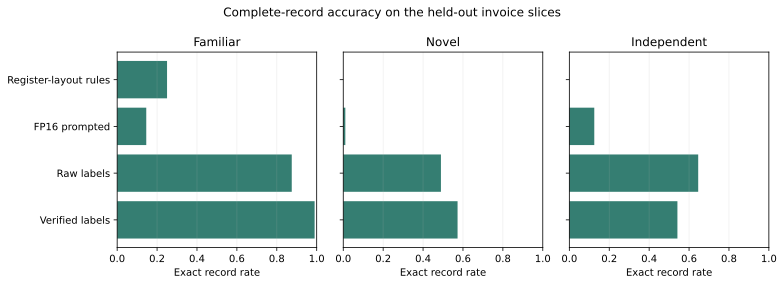

Worked training record SF-460242
both_wrong SF-265176 novel
fixed SF-797533 novel
regressed SF-781239 novel
Result files: 02-report.json, 02-predictions.json, 02-audit.json, 02-exact.svg in results/


In [14]:
paired_counts, paired_examples = paired_evidence(scores, evaluation_items)
report = save_results(
    "02", scores, training, [(RAW, VERIFIED)],
    catalogue_version=CATALOG_VERSION, split_counts=split_counts,
    label_audit=dict(ledger), candidate_rows=len(lineage), matched_rows=len(raw),
    exemplar_key=exemplar.key, family_coverage=coverage, planned_exposure=expected_budget,
    evaluation_layout_counts=evaluation_layout_counts,
    paired_exact_counts=paired_counts, batch_size=BATCH, learning_rate=LEARNING_RATE,
    fault_period=FAULT_PERIOD, max_new_tokens=MAX_NEW_TOKENS,
    accelerate_version=importlib.metadata.version("accelerate"),
)
evidence = write_audit_evidence(raw, verified, lineage, evaluation_items, paired_examples)
print("Worked training record", evidence["changed_labels"][0]["invoice_key"])
for outcome, example in paired_examples.items():
    print(outcome, example["invoice_key"], example["split"])
print("Result files: 02-report.json, 02-predictions.json, 02-audit.json, 02-exact.svg in results/")

## Read the result

Compare the paired exact counts first, then inspect field and row metrics to see what
changed. Follow the worked training invoice into the audit file. For a follow-up,
change `FAULT_PERIOD` and rerun both arms on the original held-out roster.

[Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/1-build-the-data/02-audit-synthetic-data) for the full interpretation.
[Self-Instruct](https://aclanthology.org/2023.acl-long.754/) documents a generated
instruction pipeline and a manual audit of its remaining label errors.